In [1]:

# ================================================================
# PROJET : SENTIMENT ANALYSIS BASED ON MACHINE LEARNING MODELS
# EDA + PRETRAITEMENT + TF-IDF + 4 MODELES + 4 CONTRIBUTIONS
#
# Modeles :
# 1. KNN
# 2. Random Forest
# 3. Multinomial Naive Bayes
# 4. Logistic Regression
#
# Datasets : SST-2 et IMDB
#
# Contrib:
# 2. Impact de la longueur des textes
# 3. Explicabilite (XAI) et analyse des erreurs
# 4. Robustesse au bruit lexical
# 5. Ablation de la taille du vocabulaire TF-IDF
# ================================================================

In [2]:
# ================================================================
# ETAPE 2 : IMPORTATIONS
# ================================================================

import re
import random
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from datasets import load_dataset

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

nltk.download("stopwords", quiet=True)

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print("Bibliotheques importees avec succes.")

Bibliotheques importees avec succes.


In [3]:
# ================================================================
# ETAPE 3 : CHARGEMENT DES DATASETS
# ================================================================

print("\nChargement de SST-2...")
dataset_sst2 = load_dataset("stanfordnlp/sst2")

print("Chargement de IMDB...")
dataset_imdb = load_dataset("stanfordnlp/imdb")

print("Datasets charges avec succes.")


Chargement de SST-2...


Chargement de IMDB...
Datasets charges avec succes.



Dimensions SST-2 : (68221, 4)
Dimensions IMDB  : (50000, 4)

Valeurs manquantes SST-2 :
text     0
label    0
dtype: int64

Valeurs manquantes IMDB :
text     0
label    0
dtype: int64

Doublons SST-2 : 371
Doublons IMDB  : 418

Repartition SST-2 :
sentiment
Positif    38013
Negatif    30208
Name: count, dtype: int64

Repartition IMDB :
sentiment
Negatif    25000
Positif    25000
Name: count, dtype: int64

Statistiques des longueurs SST-2 :
       nb_caracteres   nb_mots
count       68221.00  68221.00
mean           54.17      9.54
std            43.87      8.16
min             2.00      1.00
25%            21.00      3.00
50%            39.00      7.00
75%            75.00     14.00
max           268.00     52.00

Statistiques des longueurs IMDB :
       nb_caracteres   nb_mots
count       50000.00  50000.00
mean         1309.43    231.16
std           989.73    171.34
min            32.00      4.00
25%           699.00    126.00
50%           970.00    173.00
75%          1590.25   

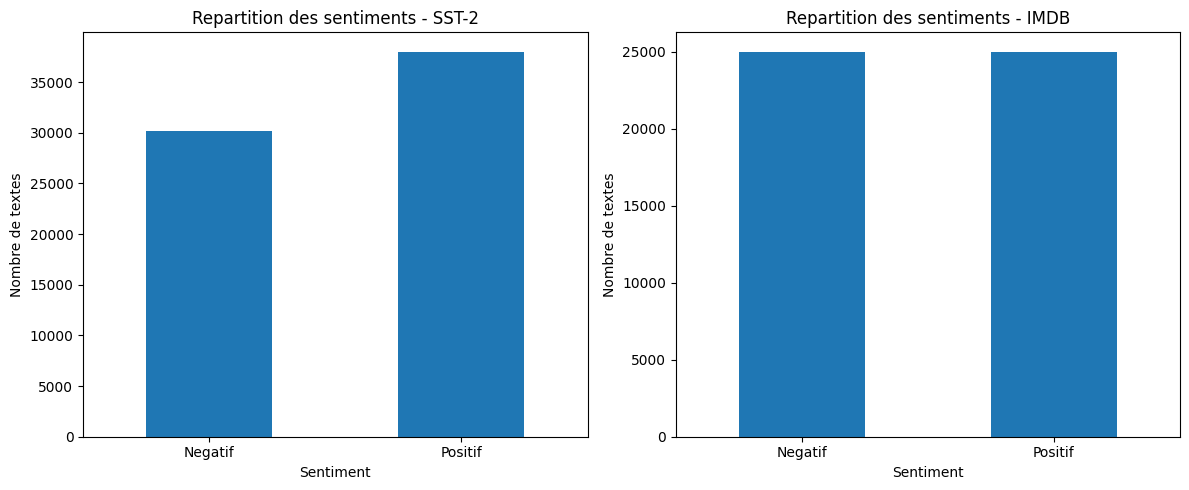

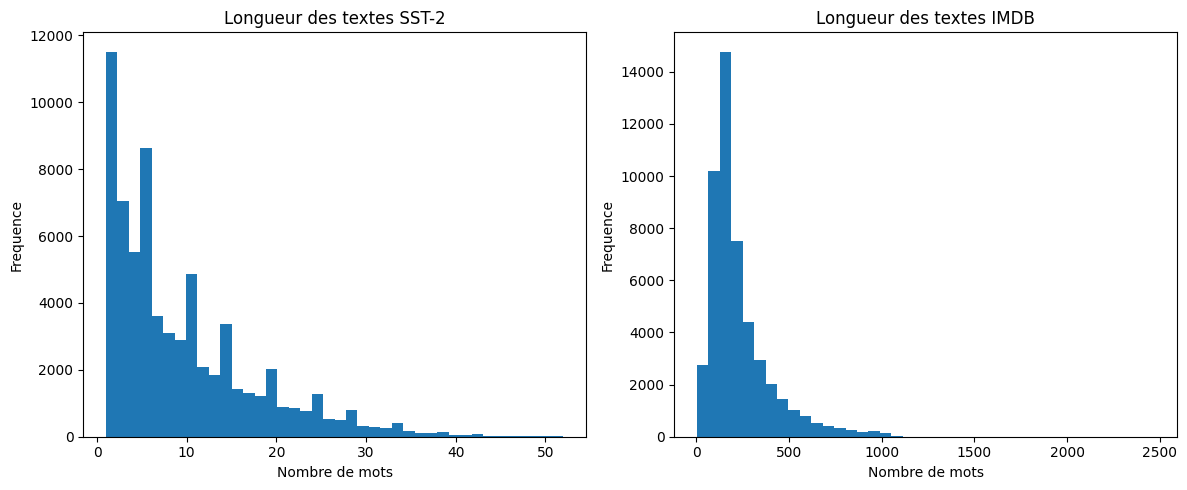


Mots frequents - SST-2 :
       Mot  Frequence
      film       4177
     movie       3825
         n       2402
       one       2179
      like       1881
      good       1535
     story       1440
     funny       1179
characters       1172
    comedy       1132
      time       1063
      well       1058
      even       1042
      much       1029
       bad        973
    little        945
      life        912
       way        881
      best        858
      love        807


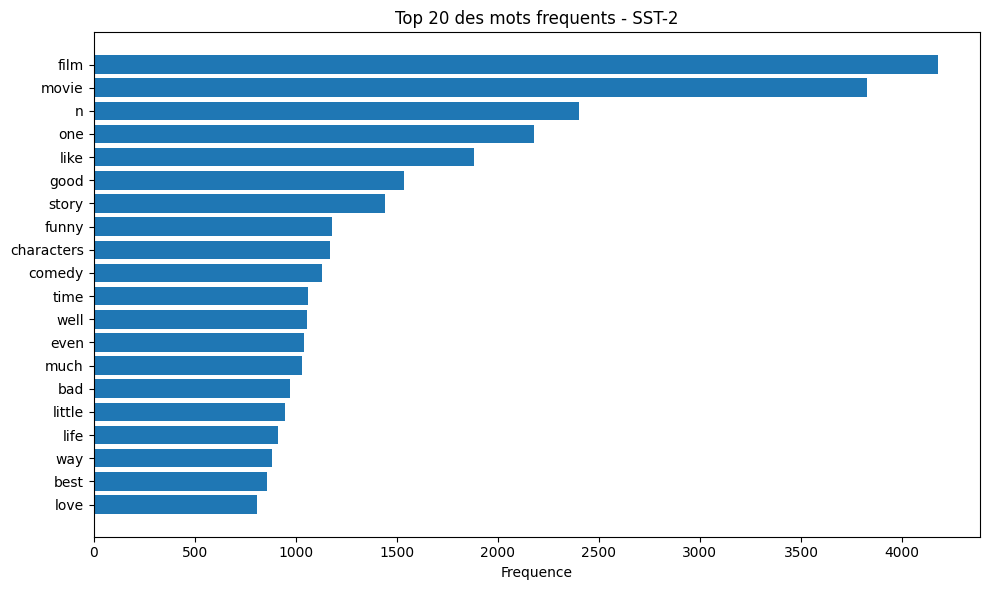


Mots frequents - IMDB :
   Mot  Frequence
    br     201951
 movie      87971
  film      79705
   one      53603
  like      40172
  good      29753
  time      25110
  even      24871
 would      24602
 story      23119
really      23094
   see      23029
  well      21268
  much      19318
   bad      18473
   get      18421
people      18188
 great      18144
  also      17977
 first      17583


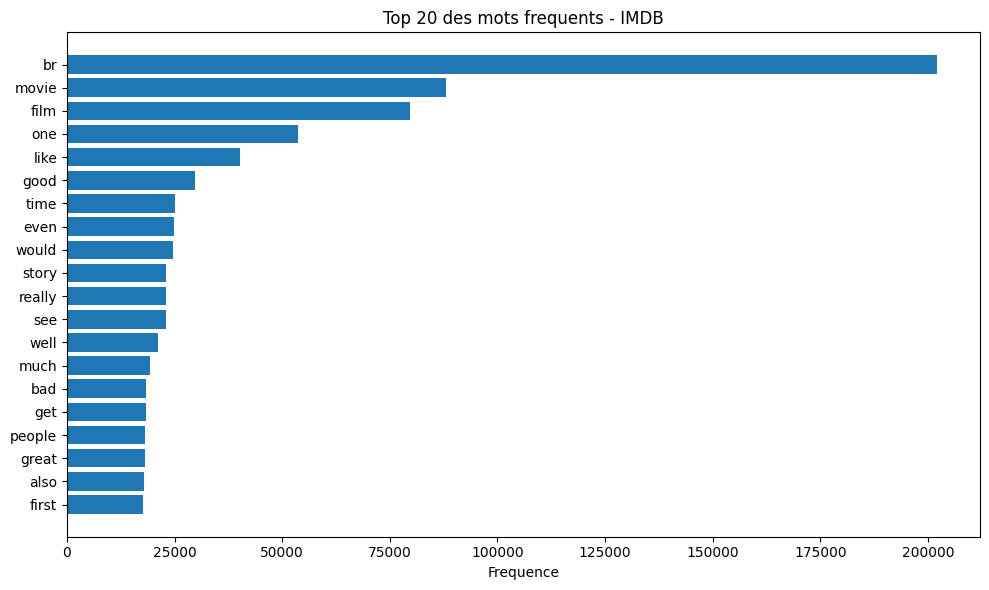


Synthese EDA :
Dataset  Nombre de textes  Valeurs manquantes  Doublons  Mots moyens  Mots medians
  SST-2             68221                   0       371         9.54           7.0
   IMDB             50000                   0       418       231.16         173.0


In [4]:
# ================================================================
# ETAPE 4 : ANALYSE EXPLORATOIRE (EDA)
# ================================================================

df_sst2 = pd.DataFrame({
    "text": dataset_sst2["train"]["sentence"],
    "label": dataset_sst2["train"]["label"],
    "split": "train"
})

if "validation" in dataset_sst2:
    df_sst2_validation = pd.DataFrame({
        "text": dataset_sst2["validation"]["sentence"],
        "label": dataset_sst2["validation"]["label"],
        "split": "validation"
    })

    df_sst2 = pd.concat(
        [df_sst2, df_sst2_validation],
        ignore_index=True
    )

df_imdb_train = pd.DataFrame({
    "text": dataset_imdb["train"]["text"],
    "label": dataset_imdb["train"]["label"],
    "split": "train"
})

df_imdb_test = pd.DataFrame({
    "text": dataset_imdb["test"]["text"],
    "label": dataset_imdb["test"]["label"],
    "split": "test"
})

df_imdb = pd.concat(
    [df_imdb_train, df_imdb_test],
    ignore_index=True
)

label_names = {
    0: "Negatif",
    1: "Positif"
}

df_sst2["sentiment"] = df_sst2["label"].map(label_names)
df_imdb["sentiment"] = df_imdb["label"].map(label_names)

print("\nDimensions SST-2 :", df_sst2.shape)
print("Dimensions IMDB  :", df_imdb.shape)

print("\nValeurs manquantes SST-2 :")
print(df_sst2[["text", "label"]].isnull().sum())

print("\nValeurs manquantes IMDB :")
print(df_imdb[["text", "label"]].isnull().sum())

print("\nDoublons SST-2 :", df_sst2["text"].duplicated().sum())
print("Doublons IMDB  :", df_imdb["text"].duplicated().sum())

print("\nRepartition SST-2 :")
print(df_sst2["sentiment"].value_counts())

print("\nRepartition IMDB :")
print(df_imdb["sentiment"].value_counts())

# Longueurs des textes
for df in [df_sst2, df_imdb]:
    df["nb_caracteres"] = df["text"].astype(str).str.len()
    df["nb_mots"] = df["text"].astype(str).str.split().str.len()

print("\nStatistiques des longueurs SST-2 :")
print(df_sst2[["nb_caracteres", "nb_mots"]].describe().round(2))

print("\nStatistiques des longueurs IMDB :")
print(df_imdb[["nb_caracteres", "nb_mots"]].describe().round(2))

# Graphique de la repartition des sentiments
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, df, titre in [
    (axes[0], df_sst2, "SST-2"),
    (axes[1], df_imdb, "IMDB")
]:
    counts = df["sentiment"].value_counts().reindex(
        ["Negatif", "Positif"],
        fill_value=0
    )

    counts.plot(kind="bar", ax=ax)
    ax.set_title(f"Repartition des sentiments - {titre}")
    ax.set_xlabel("Sentiment")
    ax.set_ylabel("Nombre de textes")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

# Histogrammes des longueurs
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(df_sst2["nb_mots"], bins=40)
axes[0].set_title("Longueur des textes SST-2")
axes[0].set_xlabel("Nombre de mots")
axes[0].set_ylabel("Frequence")

axes[1].hist(df_imdb["nb_mots"], bins=40)
axes[1].set_title("Longueur des textes IMDB")
axes[1].set_xlabel("Nombre de mots")
axes[1].set_ylabel("Frequence")

plt.tight_layout()
plt.show()

# Mots les plus frequents
stop_words_eda = set(stopwords.words("english"))

def get_most_frequent_words(texts, n=20):
    words = []

    for text in texts:
        tokens = re.findall(r"\b[a-z]+\b", str(text).lower())
        words.extend([
            word for word in tokens
            if word not in stop_words_eda
        ])

    return Counter(words).most_common(n)


def plot_most_frequent_words(df, title, n=20):
    frequent_words = get_most_frequent_words(df["text"], n)

    words_df = pd.DataFrame(
        frequent_words,
        columns=["Mot", "Frequence"]
    )

    print(f"\nMots frequents - {title} :")
    print(words_df.to_string(index=False))

    if words_df.empty:
        return

    plt.figure(figsize=(10, 6))
    plt.barh(
        words_df["Mot"][::-1],
        words_df["Frequence"][::-1]
    )
    plt.title(f"Top {n} des mots frequents - {title}")
    plt.xlabel("Frequence")
    plt.tight_layout()
    plt.show()


plot_most_frequent_words(df_sst2, "SST-2")
plot_most_frequent_words(df_imdb, "IMDB")

# Sauvegarde de l'EDA
eda_summary = pd.DataFrame([
    {
        "Dataset": "SST-2",
        "Nombre de textes": len(df_sst2),
        "Valeurs manquantes": df_sst2["text"].isnull().sum(),
        "Doublons": df_sst2["text"].duplicated().sum(),
        "Mots moyens": df_sst2["nb_mots"].mean(),
        "Mots medians": df_sst2["nb_mots"].median()
    },
    {
        "Dataset": "IMDB",
        "Nombre de textes": len(df_imdb),
        "Valeurs manquantes": df_imdb["text"].isnull().sum(),
        "Doublons": df_imdb["text"].duplicated().sum(),
        "Mots moyens": df_imdb["nb_mots"].mean(),
        "Mots medians": df_imdb["nb_mots"].median()
    }
])

print("\nSynthese EDA :")
print(eda_summary.round(2).to_string(index=False))

In [5]:
# ================================================================
# ETAPE 5 : PREPARATION DES DONNEES
# ================================================================

texts_sst2 = list(dataset_sst2["train"]["sentence"])
labels_sst2 = np.array(dataset_sst2["train"]["label"])

X_train_text, X_test_sst2_text, y_train, y_test_sst2 = (
    train_test_split(
        texts_sst2,
        labels_sst2,
        train_size=50000,
        random_state=SEED,
        stratify=labels_sst2
    )
)

imdb_test = dataset_imdb["test"].shuffle(
    seed=SEED
).select(range(10000))

X_test_imdb_text = list(imdb_test["text"])
y_test_imdb = np.array(imdb_test["label"])

print("\nTaille train SST-2 :", len(X_train_text))
print("Taille test SST-2  :", len(X_test_sst2_text))
print("Taille test IMDB   :", len(X_test_imdb_text))



Taille train SST-2 : 50000
Taille test SST-2  : 17349
Taille test IMDB   : 10000


In [6]:
# ================================================================
# ETAPE 6 : PRETRAITEMENT DES TEXTES
# ================================================================

stop_words = set(stopwords.words("english"))

# Preserver les negations importantes pour le sentiment
for word in ["no", "nor", "not"]:
    stop_words.discard(word)

stemmer = PorterStemmer()


def preprocess_text(text):
    text = str(text).lower()

    # Tokenisation et suppression de la ponctuation
    tokens = re.findall(r"\b[a-z]+\b", text)

    # Suppression des stopwords
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # Stemming
    tokens = [
        stemmer.stem(word)
        for word in tokens
    ]

    return " ".join(tokens)


print("\nPretraitement des textes...")

X_train_clean = [
    preprocess_text(text) for text in X_train_text
]

X_test_sst2_clean = [
    preprocess_text(text) for text in X_test_sst2_text
]

X_test_imdb_clean = [
    preprocess_text(text) for text in X_test_imdb_text
]

print("Pretraitement termine.")


Pretraitement des textes...
Pretraitement termine.


In [7]:
# ================================================================
# ETAPE 7 : REPRESENTATION TF-IDF
# ================================================================

print("\nTransformation TF-IDF...")

vectorizer = TfidfVectorizer(max_features=20000)

X_train_tfidf = vectorizer.fit_transform(X_train_clean)

X_test_sst2_tfidf = vectorizer.transform(X_test_sst2_clean)

X_test_imdb_tfidf = vectorizer.transform(X_test_imdb_clean)

print("Dimensions train :", X_train_tfidf.shape)
print("Dimensions SST-2 :", X_test_sst2_tfidf.shape)
print("Dimensions IMDB  :", X_test_imdb_tfidf.shape)


Transformation TF-IDF...
Dimensions train : (50000, 9461)
Dimensions SST-2 : (17349, 9461)
Dimensions IMDB  : (10000, 9461)


In [8]:
# ================================================================
# ETAPE 8 : DEFINITION DES MODELES
# ================================================================

models = {
    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=8,
        bootstrap=True,
        random_state=SEED,
        n_jobs=-1
    ),

    "Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=SEED
    )
}

In [9]:
# ================================================================
# ETAPE 9 : FONCTIONS D'EVALUATION
# ================================================================

def predict_in_batches(model, X, batch_size=200):
    predictions_list = []

    for start in range(0, X.shape[0], batch_size):
        end = min(start + batch_size, X.shape[0])
        predictions_list.extend(model.predict(X[start:end]))

    return np.array(predictions_list)


def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        )
    }

In [10]:
# ================================================================
# ETAPE 10 : ENTRAINEMENT ET EVALUATION
# ================================================================

results = []
predictions = {}

for model_name, model in models.items():

    print("\n" + "=" * 60)
    print("MODELE :", model_name)
    print("=" * 60)

    print("Entrainement sur SST-2...")
    model.fit(X_train_tfidf, y_train)

    # Evaluation sur SST-2
    if model_name == "KNN":
        y_pred_sst2 = predict_in_batches(
            model, X_test_sst2_tfidf
        )
    else:
        y_pred_sst2 = model.predict(X_test_sst2_tfidf)

    metrics_sst2 = calculate_metrics(
        y_test_sst2, y_pred_sst2
    )

    results.append({
        "Modele": model_name,
        "Dataset": "SST-2",
        **metrics_sst2
    })

    predictions[(model_name, "SST-2")] = y_pred_sst2

    print("Resultats SST-2 :", metrics_sst2)

    # Evaluation sur IMDB
    if model_name == "KNN":
        y_pred_imdb = predict_in_batches(
            model, X_test_imdb_tfidf
        )
    else:
        y_pred_imdb = model.predict(X_test_imdb_tfidf)

    metrics_imdb = calculate_metrics(
        y_test_imdb, y_pred_imdb
    )

    results.append({
        "Modele": model_name,
        "Dataset": "IMDB",
        **metrics_imdb
    })

    predictions[(model_name, "IMDB")] = y_pred_imdb

    print("Resultats IMDB :", metrics_imdb)


MODELE : KNN
Entrainement sur SST-2...
Resultats SST-2 : {'Accuracy': 0.8896189982131535, 'Precision': 0.8927451178791865, 'Recall': 0.9116553006819591, 'F1-score': 0.9021011195746639}
Resultats IMDB : {'Accuracy': 0.5919, 'Precision': 0.5704171155918116, 'Recall': 0.7417934347477982, 'F1-score': 0.6449142956582268}

MODELE : Random Forest
Entrainement sur SST-2...
Resultats SST-2 : {'Accuracy': 0.8983226698945184, 'Precision': 0.9046839844548987, 'Recall': 0.9140318247571813, 'F1-score': 0.9093338815789473}
Resultats IMDB : {'Accuracy': 0.6672, 'Precision': 0.7271241830065359, 'Recall': 0.5344275420336269, 'F1-score': 0.6160590678357176}

MODELE : Naive Bayes
Entrainement sur SST-2...
Resultats SST-2 : {'Accuracy': 0.8746325436624589, 'Precision': 0.8699339315649344, 'Recall': 0.9115519735482538, 'F1-score': 0.8902568242595489}
Resultats IMDB : {'Accuracy': 0.7982, 'Precision': 0.8358141632837167, 'Recall': 0.7417934347477982, 'F1-score': 0.7860021208907741}

MODELE : Logistic Regres

In [11]:
# ================================================================
# ETAPE 11 : TABLEAU DES RESULTATS
# ================================================================

results_df = pd.DataFrame(results)

print("\nRESULTATS EXPERIMENTAUX :")
print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    "resultats_sentiment_analysis.csv",
    index=False,
    encoding="utf-8"
)


RESULTATS EXPERIMENTAUX :
             Modele Dataset  Accuracy  Precision  Recall  F1-score
                KNN   SST-2    0.8896     0.8927  0.9117    0.9021
                KNN    IMDB    0.5919     0.5704  0.7418    0.6449
      Random Forest   SST-2    0.8983     0.9047  0.9140    0.9093
      Random Forest    IMDB    0.6672     0.7271  0.5344    0.6161
        Naive Bayes   SST-2    0.8746     0.8699  0.9116    0.8903
        Naive Bayes    IMDB    0.7982     0.8358  0.7418    0.7860
Logistic Regression   SST-2    0.8806     0.8857  0.9025    0.8940
Logistic Regression    IMDB    0.8127     0.8400  0.7722    0.8047


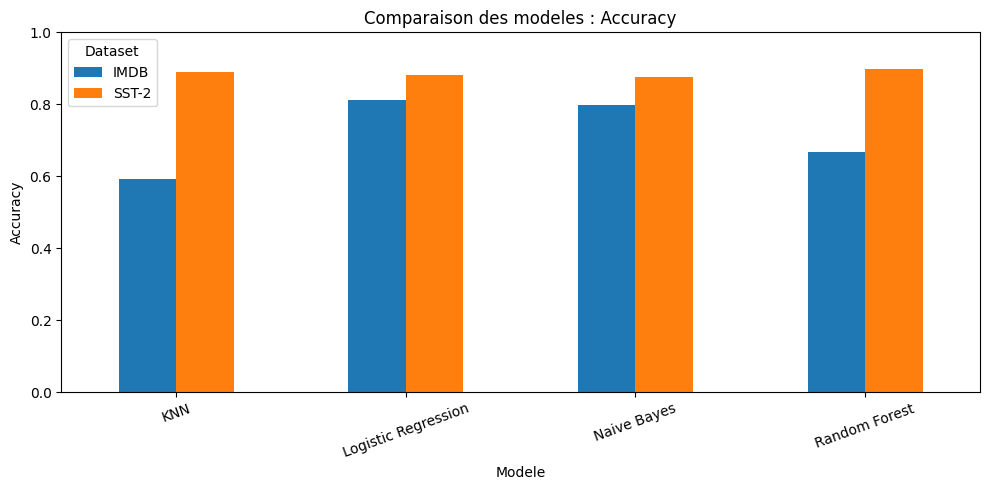

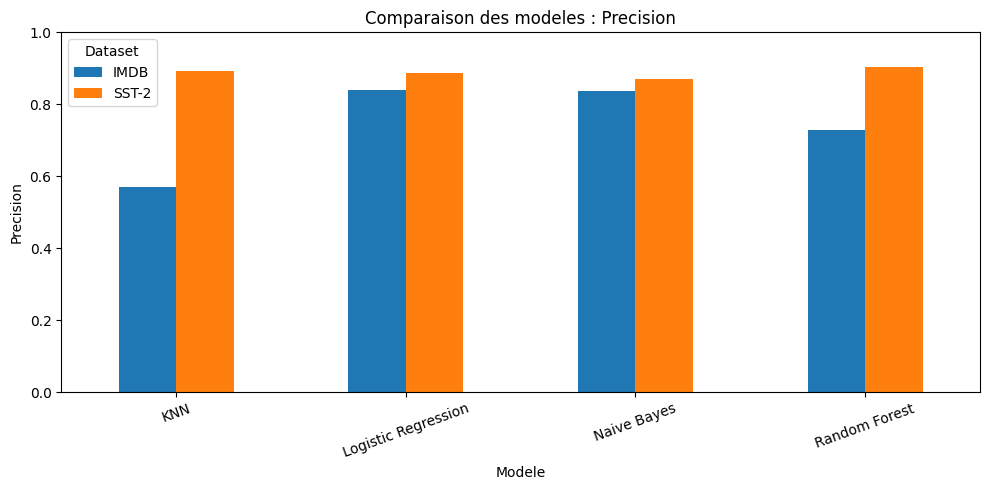

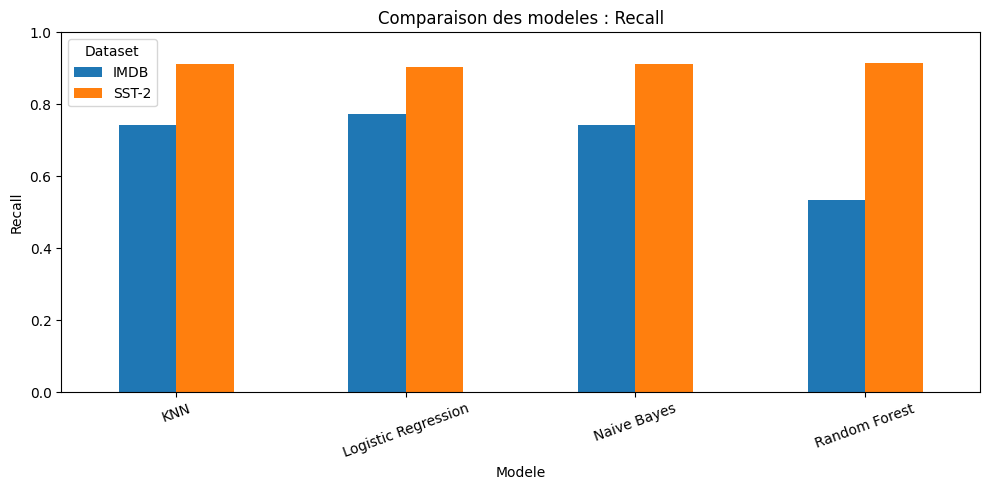

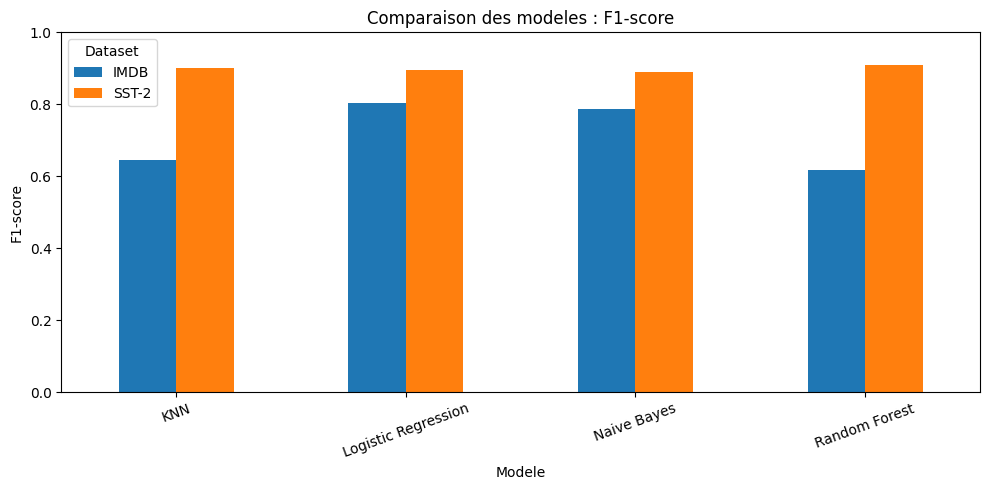

In [12]:
# ================================================================
# ETAPE 12 : COMPARAISON GRAPHIQUE
# ================================================================

for metric in ["Accuracy", "Precision", "Recall", "F1-score"]:

    pivot_df = results_df.pivot(
        index="Modele",
        columns="Dataset",
        values=metric
    )

    ax = pivot_df.plot(kind="bar", figsize=(10, 5))

    ax.set_title(f"Comparaison des modeles : {metric}")
    ax.set_xlabel("Modele")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)

    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

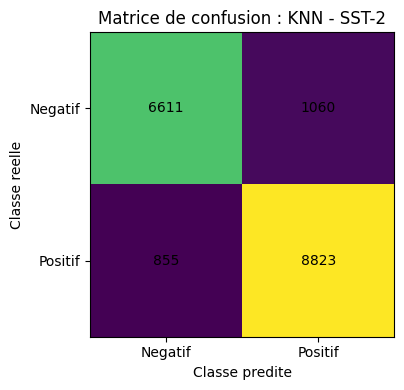

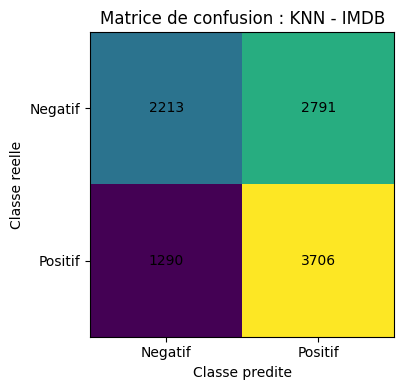

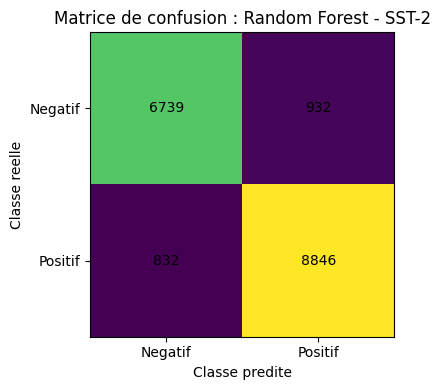

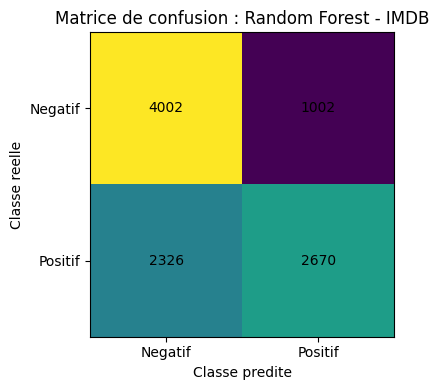

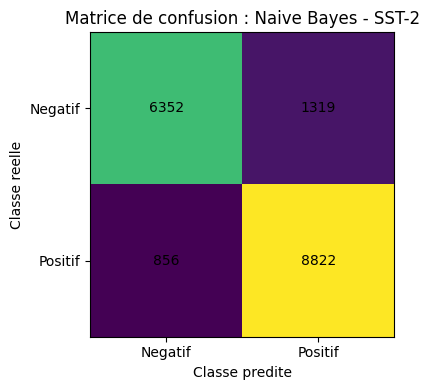

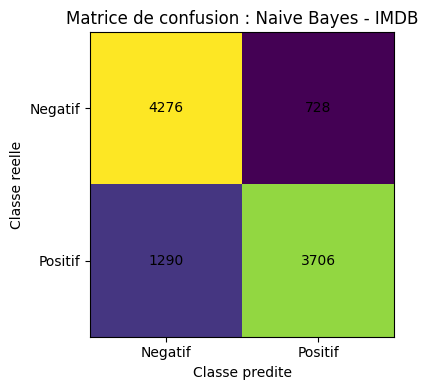

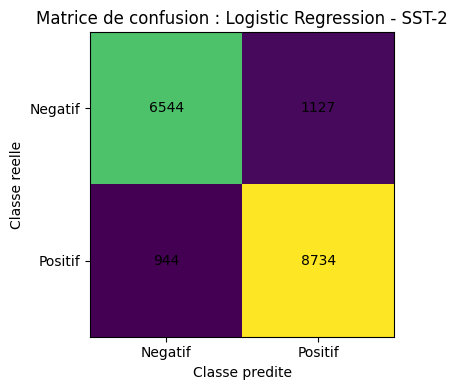

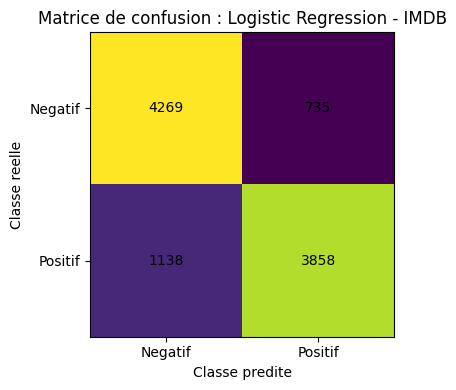

In [13]:
# ================================================================
# ETAPE 13 : MATRICES DE CONFUSION
# ================================================================

for model_name in models.keys():

    for dataset_name, y_true in [
        ("SST-2", y_test_sst2),
        ("IMDB", y_test_imdb)
    ]:

        y_pred = predictions[(model_name, dataset_name)]

        cm = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        )

        plt.figure(figsize=(5, 4))
        plt.imshow(cm)

        plt.title(
            f"Matrice de confusion : {model_name} - {dataset_name}"
        )

        plt.xlabel("Classe predite")
        plt.ylabel("Classe reelle")

        plt.xticks([0, 1], ["Negatif", "Positif"])
        plt.yticks([0, 1], ["Negatif", "Positif"])

        for i in range(2):
            for j in range(2):
                plt.text(
                    j, i, str(cm[i, j]),
                    ha="center", va="center"
                )

        plt.tight_layout()
        plt.show()

In [14]:
# ================================================================
# ETAPE 14 : RAPPORTS DE CLASSIFICATION
# ================================================================

for model_name in models.keys():

    for dataset_name, y_true in [
        ("SST-2", y_test_sst2),
        ("IMDB", y_test_imdb)
    ]:

        y_pred = predictions[(model_name, dataset_name)]

        print("\n" + "=" * 60)
        print(f"{model_name} - {dataset_name}")
        print("=" * 60)

        print(classification_report(
            y_true,
            y_pred,
            labels=[0, 1],
            target_names=["Negatif", "Positif"],
            digits=4,
            zero_division=0
        ))


KNN - SST-2
              precision    recall  f1-score   support

     Negatif     0.8855    0.8618    0.8735      7671
     Positif     0.8927    0.9117    0.9021      9678

    accuracy                         0.8896     17349
   macro avg     0.8891    0.8867    0.8878     17349
weighted avg     0.8895    0.8896    0.8894     17349


KNN - IMDB
              precision    recall  f1-score   support

     Negatif     0.6317    0.4422    0.5203      5004
     Positif     0.5704    0.7418    0.6449      4996

    accuracy                         0.5919     10000
   macro avg     0.6011    0.5920    0.5826     10000
weighted avg     0.6011    0.5919    0.5825     10000


Random Forest - SST-2
              precision    recall  f1-score   support

     Negatif     0.8901    0.8785    0.8843      7671
     Positif     0.9047    0.9140    0.9093      9678

    accuracy                         0.8983     17349
   macro avg     0.8974    0.8963    0.8968     17349
weighted avg     0.8982   


CONTRIBUTION 2 : IMPACT DE LA LONGUEUR
Nombre total : 10000
Textes courts : 7
Textes longs : 9993

Resultats selon la longueur :
             Modele        Groupe  Nombre de textes  Accuracy  F1-score
                KNN Textes courts                 7    0.7143    0.6667
                KNN  Textes longs              9993    0.5918    0.6449
      Random Forest Textes courts                 7    1.0000    1.0000
      Random Forest  Textes longs              9993    0.6670    0.6159
        Naive Bayes Textes courts                 7    0.7143    0.6667
        Naive Bayes  Textes longs              9993    0.7983    0.7861
Logistic Regression Textes courts                 7    1.0000    1.0000
Logistic Regression  Textes longs              9993    0.8126    0.8046


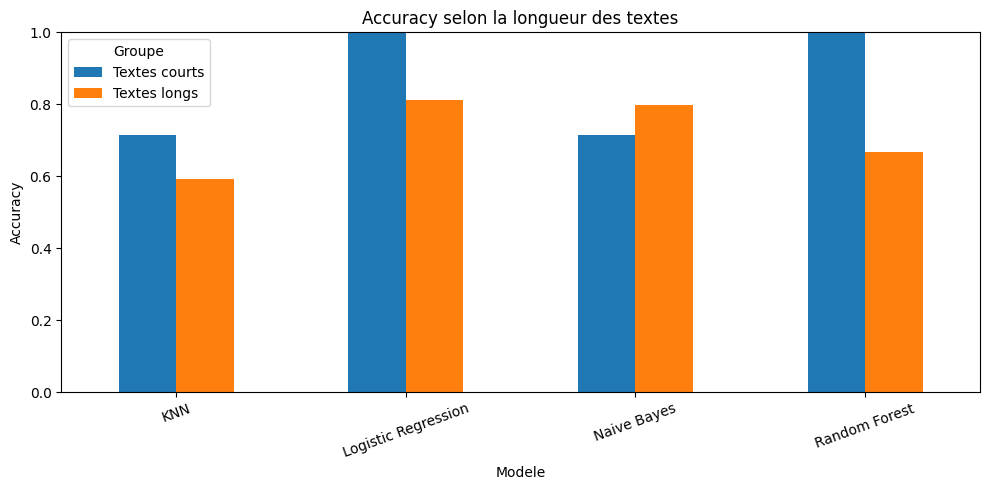

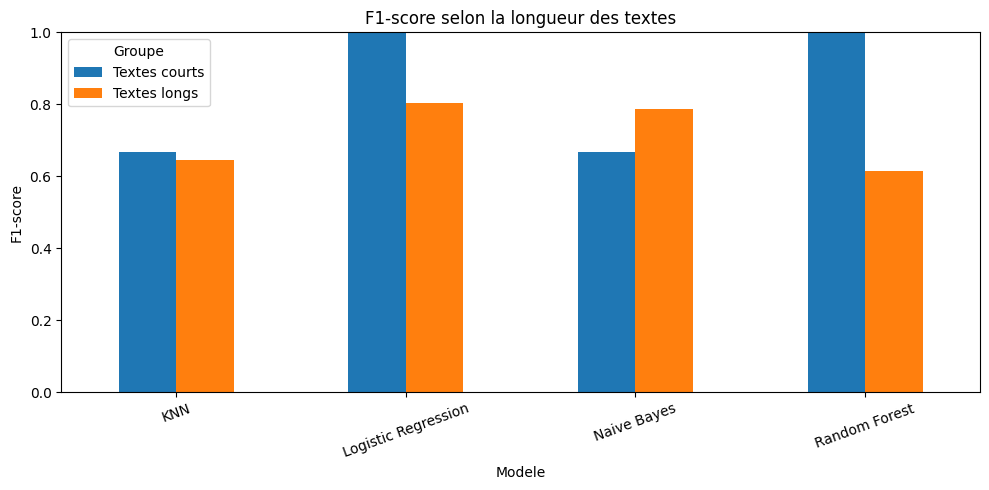

In [15]:
# ================================================================
# ETAPE 15 : CONTRIBUTION 2
# IMPACT DE LA LONGUEUR DES TEXTES
# ================================================================

print("\n" + "=" * 70)
print("CONTRIBUTION 2 : IMPACT DE LA LONGUEUR")
print("=" * 70)

seuil_longueur = 20

longueurs = np.array([
    len(str(texte).split())
    for texte in X_test_imdb_text
])

indices_courts = np.where(longueurs <= seuil_longueur)[0]
indices_longs = np.where(longueurs > seuil_longueur)[0]

print("Nombre total :", len(longueurs))
print("Textes courts :", len(indices_courts))
print("Textes longs :", len(indices_longs))

if len(indices_courts) == 0 or len(indices_longs) == 0:
    raise ValueError("Un groupe de longueur est vide.")

results_longueur = []

for model_name in models.keys():

    y_pred = predictions[(model_name, "IMDB")]

    for groupe, indices in [
        ("Textes courts", indices_courts),
        ("Textes longs", indices_longs)
    ]:

        y_true_groupe = y_test_imdb[indices]
        y_pred_groupe = y_pred[indices]

        results_longueur.append({
            "Modele": model_name,
            "Groupe": groupe,
            "Nombre de textes": len(indices),
            "Accuracy": accuracy_score(
                y_true_groupe, y_pred_groupe
            ),
            "F1-score": f1_score(
                y_true_groupe, y_pred_groupe,
                zero_division=0
            )
        })

df_longueur = pd.DataFrame(results_longueur)

print("\nResultats selon la longueur :")
print(df_longueur.round(4).to_string(index=False))

df_longueur.to_csv(
    "contribution2_longueur.csv",
    index=False,
    encoding="utf-8"
)

for metric in ["Accuracy", "F1-score"]:

    tableau = df_longueur.pivot(
        index="Modele",
        columns="Groupe",
        values=metric
    )

    tableau.plot(kind="bar", figsize=(10, 5))
    plt.title(f"{metric} selon la longueur des textes")
    plt.ylabel(metric)
    plt.xlabel("Modele")
    plt.ylim(0, 1)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()



CONTRIBUTION 3 : XAI ET ANALYSE DES ERREURS

Mots les plus associes aux sentiments :
Mots negatifs  Coefficient negatif Mots positifs  Coefficient positif
         lack              -6.7833        beauti               4.7804
        worst              -5.5032          best               4.7209
          bad              -5.2034        hilari               4.2794
         fail              -4.9621         power               4.2238
         none              -4.7443        fascin               4.1065
         wast              -4.5917       refresh               3.9960
         dull              -4.4388         enjoy               3.9771
         mess              -4.3275           fun               3.8655
           no              -4.3168          love               3.7960
       devoid              -4.1983        terrif               3.7162


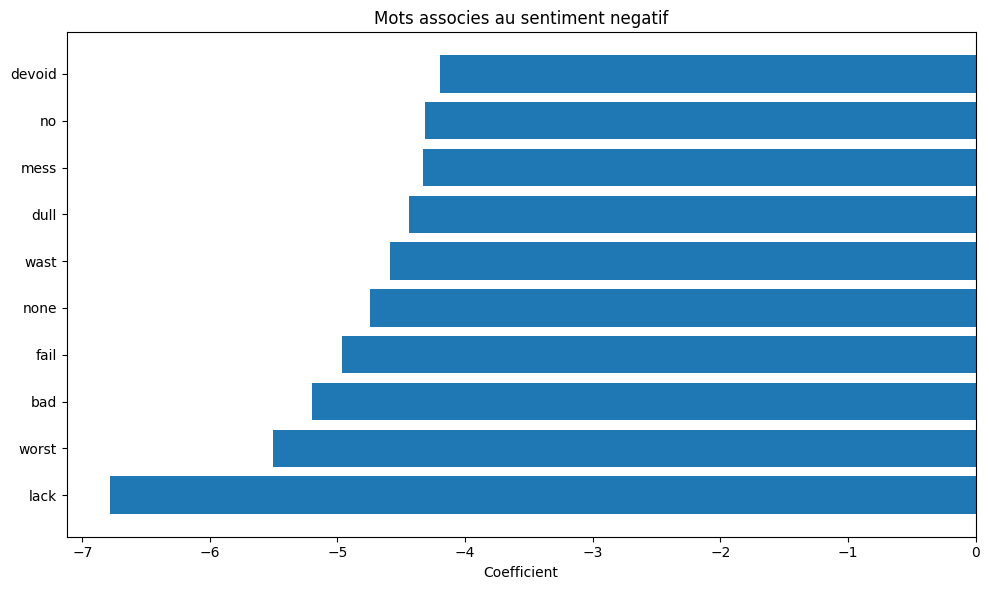

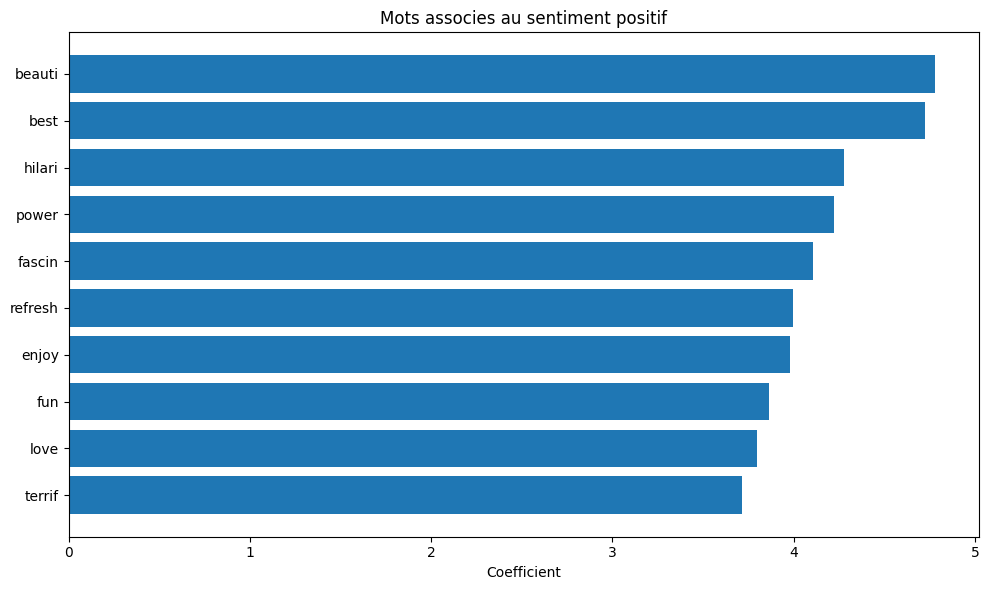


Exemple d'erreur de classification :
Texte : This is the latest entry in the long series of films with the French agent, O.S.S. 117 (the French answer to James Bond). The series was launched in the early 1950's, and spawned at least eight films (none of which was ever released in the U.S.). 'O.S.S.117:Cairo,Nest Of Spies' is a breezy little comedy that should not...repeat NOT, be taken too seriously. Our protagonist finds himself in the middle of a spy chase in Egypt (with Morroco doing stand in for Egypt) to find out about a long lost friend. What follows is the standard James Bond/Inspector Cloussou kind of antics. Although our man is something of an overt xenophobe,sexist,homophobe, it's treated as pure farce (as I said, don't take it too seriously). Although there is a bit of rough language & cartoon violence, it's basically okay for older kids (ages 12 & up). As previously stated in the subject line, just sit back,pass the popcorn & just enjoy.
Sentiment reel : Positif
Sentiment 

In [16]:
# ================================================================
# ETAPE 16 : CONTRIBUTION 3
# EXPLICABILITE ET ANALYSE DES ERREURS
# ================================================================

print("\n" + "=" * 70)
print("CONTRIBUTION 3 : XAI ET ANALYSE DES ERREURS")
print("=" * 70)

log_reg = models["Logistic Regression"]

feature_names = np.array(vectorizer.get_feature_names_out())
coefs = log_reg.coef_[0]

top_negative_idx = np.argsort(coefs)[:10]
top_positive_idx = np.argsort(coefs)[-10:][::-1]

df_mots_cles = pd.DataFrame({
    "Mots negatifs": feature_names[top_negative_idx],
    "Coefficient negatif": np.round(coefs[top_negative_idx], 4),
    "Mots positifs": feature_names[top_positive_idx],
    "Coefficient positif": np.round(coefs[top_positive_idx], 4)
})

print("\nMots les plus associes aux sentiments :")
print(df_mots_cles.to_string(index=False))

df_mots_cles.to_csv(
    "contribution3_mots_influents.csv",
    index=False,
    encoding="utf-8"
)

plt.figure(figsize=(10, 6))
plt.barh(
    feature_names[top_negative_idx],
    coefs[top_negative_idx]
)
plt.title("Mots associes au sentiment negatif")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.barh(
    feature_names[top_positive_idx][::-1],
    coefs[top_positive_idx][::-1]
)
plt.title("Mots associes au sentiment positif")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

# Identifier une erreur de la regression logistique sur IMDB
y_pred_lr_imdb = predictions[
    ("Logistic Regression", "IMDB")
]

indices_erreurs = np.where(
    y_test_imdb != y_pred_lr_imdb
)[0]

if len(indices_erreurs) > 0:

    idx_erreur = int(indices_erreurs[0])

    noms_sentiments = {
        0: "Negatif",
        1: "Positif"
    }

    print("\nExemple d'erreur de classification :")
    print("Texte :", str(X_test_imdb_text[idx_erreur])[:1500])
    print(
        "Sentiment reel :",
        noms_sentiments[int(y_test_imdb[idx_erreur])]
    )
    print(
        "Sentiment predit :",
        noms_sentiments[int(y_pred_lr_imdb[idx_erreur])]
    )

    pd.DataFrame([{
        "Index": idx_erreur,
        "Texte": X_test_imdb_text[idx_erreur],
        "Sentiment reel": noms_sentiments[
            int(y_test_imdb[idx_erreur])
        ],
        "Sentiment predit": noms_sentiments[
            int(y_pred_lr_imdb[idx_erreur])
        ]
    }]).to_csv(
        "contribution3_exemple_erreur.csv",
        index=False,
        encoding="utf-8"
    )

else:
    print("Aucune erreur trouvee.")

print("Nombre d'erreurs LR :", len(indices_erreurs))


CONTRIBUTION 4 : ROBUSTESSE AU BRUIT

Resultats de robustesse :
             Modele  Accuracy normale  Accuracy bruitee  Variation Accuracy  F1 normal  F1 bruite  Variation F1
                KNN            0.5919            0.5895             -0.0024     0.6449     0.6439       -0.0010
      Random Forest            0.6672            0.6662             -0.0010     0.6161     0.6157       -0.0004
        Naive Bayes            0.7982            0.7953             -0.0029     0.7860     0.7840       -0.0020
Logistic Regression            0.8127            0.8064             -0.0063     0.8047     0.7990       -0.0057


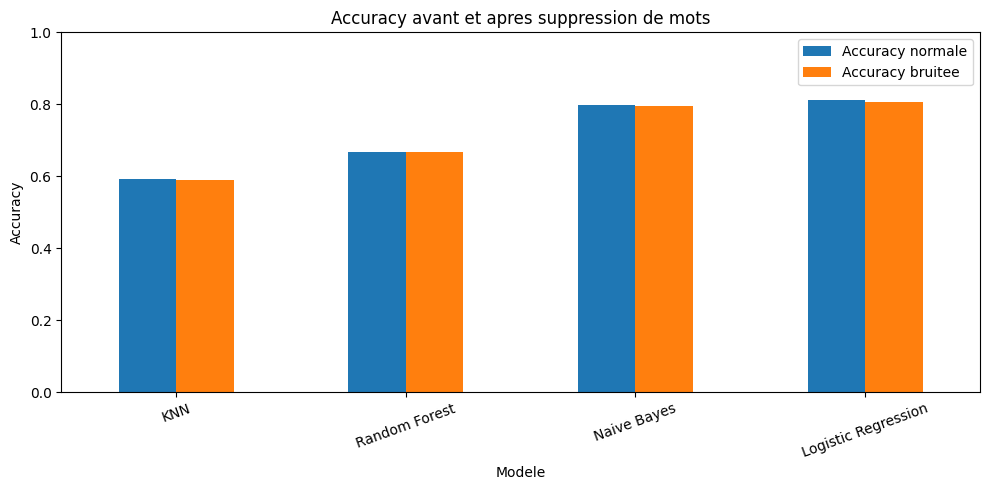

In [17]:
# ================================================================
# ETAPE 17 : CONTRIBUTION 4
# ROBUSTESSE AU BRUIT LEXICAL
# ================================================================

print("\n" + "=" * 70)
print("CONTRIBUTION 4 : ROBUSTESSE AU BRUIT")
print("=" * 70)


def ajouter_bruit(texte, proba=0.10, seed=42):

    mots = str(texte).split()

    if len(mots) <= 1:
        return str(texte)

    rng = random.Random(seed)

    mots_bruites = [
        mot for mot in mots
        if rng.random() >= proba
    ]

    if len(mots_bruites) == 0:
        mots_bruites = [mots[0]]

    return " ".join(mots_bruites)


X_test_imdb_bruite_text = [
    ajouter_bruit(texte, proba=0.10, seed=SEED + i)
    for i, texte in enumerate(X_test_imdb_text)
]

X_test_imdb_bruite_clean = [
    preprocess_text(texte)
    for texte in X_test_imdb_bruite_text
]

X_test_imdb_bruite_tfidf = vectorizer.transform(
    X_test_imdb_bruite_clean
)

results_bruit = []

for model_name, model in models.items():

    y_pred_normal = predictions[(model_name, "IMDB")]

    if model_name == "KNN":
        y_pred_bruite = predict_in_batches(
            model, X_test_imdb_bruite_tfidf
        )
    else:
        y_pred_bruite = model.predict(
            X_test_imdb_bruite_tfidf
        )

    acc_normal = accuracy_score(
        y_test_imdb, y_pred_normal
    )
    f1_normal = f1_score(
        y_test_imdb, y_pred_normal,
        zero_division=0
    )

    acc_bruite = accuracy_score(
        y_test_imdb, y_pred_bruite
    )
    f1_bruite = f1_score(
        y_test_imdb, y_pred_bruite,
        zero_division=0
    )

    results_bruit.append({
        "Modele": model_name,
        "Accuracy normale": acc_normal,
        "Accuracy bruitee": acc_bruite,
        "Variation Accuracy": acc_bruite - acc_normal,
        "F1 normal": f1_normal,
        "F1 bruite": f1_bruite,
        "Variation F1": f1_bruite - f1_normal
    })

df_bruit = pd.DataFrame(results_bruit)

print("\nResultats de robustesse :")
print(df_bruit.round(4).to_string(index=False))

df_bruit.to_csv(
    "contribution4_robustesse.csv",
    index=False,
    encoding="utf-8"
)

df_bruit.set_index("Modele")[
    ["Accuracy normale", "Accuracy bruitee"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Accuracy avant et apres suppression de mots")
plt.ylabel("Accuracy")
plt.xlabel("Modele")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


CONTRIBUTION 5 : ABLATION TF-IDF

Test avec max_features = 5000

Test avec max_features = 10000

Test avec max_features = 20000

Test avec max_features = 40000

Resultats de l'ablation :
 max_features demande  Vocabulaire reel  Accuracy SST-2  F1 SST-2  Accuracy IMDB  F1 IMDB
                 5000              5000          0.8637    0.8802         0.8113   0.8014
                10000              9461          0.8806    0.8940         0.8127   0.8047
                20000              9461          0.8806    0.8940         0.8127   0.8047
                40000              9461          0.8806    0.8940         0.8127   0.8047


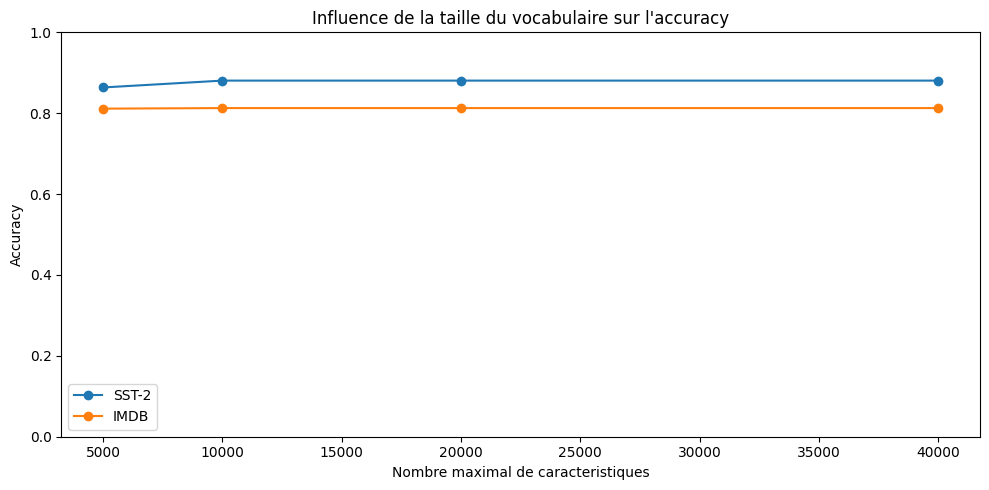

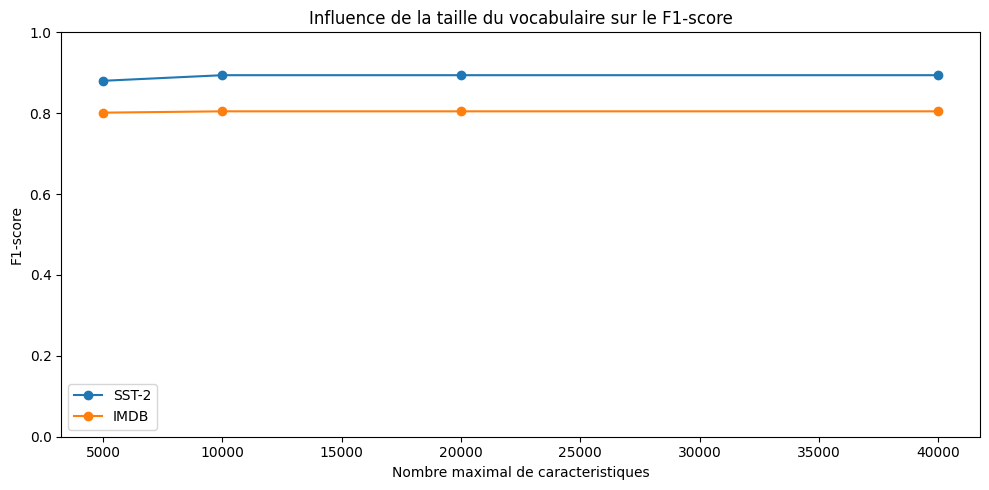

In [18]:
# ================================================================
# ETAPE 18 : CONTRIBUTION 5
# ABLATION DE LA TAILLE DU VOCABULAIRE TF-IDF
# ================================================================

print("\n" + "=" * 70)
print("CONTRIBUTION 5 : ABLATION TF-IDF")
print("=" * 70)

tailles_vocab = [5000, 10000, 20000, 40000]
results_ablation_tf = []

for max_f in tailles_vocab:

    print(f"\nTest avec max_features = {max_f}")

    vec_temp = TfidfVectorizer(max_features=max_f)

    X_tr_temp = vec_temp.fit_transform(X_train_clean)
    X_sst2_temp = vec_temp.transform(X_test_sst2_clean)
    X_imdb_temp = vec_temp.transform(X_test_imdb_clean)

    lr_temp = LogisticRegression(
        max_iter=1000,
        random_state=SEED
    )

    lr_temp.fit(X_tr_temp, y_train)

    pred_sst2_temp = lr_temp.predict(X_sst2_temp)
    pred_imdb_temp = lr_temp.predict(X_imdb_temp)

    results_ablation_tf.append({
        "max_features demande": max_f,
        "Vocabulaire reel": len(vec_temp.get_feature_names_out()),
        "Accuracy SST-2": accuracy_score(
            y_test_sst2, pred_sst2_temp
        ),
        "F1 SST-2": f1_score(
            y_test_sst2, pred_sst2_temp,
            zero_division=0
        ),
        "Accuracy IMDB": accuracy_score(
            y_test_imdb, pred_imdb_temp
        ),
        "F1 IMDB": f1_score(
            y_test_imdb, pred_imdb_temp,
            zero_division=0
        )
    })

df_ablation_tf = pd.DataFrame(results_ablation_tf)

print("\nResultats de l'ablation :")
print(df_ablation_tf.round(4).to_string(index=False))

df_ablation_tf.to_csv(
    "contribution5_ablation_tfidf.csv",
    index=False,
    encoding="utf-8"
)

# Comparaison des accuracies
plt.figure(figsize=(10, 5))

plt.plot(
    df_ablation_tf["max_features demande"],
    df_ablation_tf["Accuracy SST-2"],
    marker="o",
    label="SST-2"
)

plt.plot(
    df_ablation_tf["max_features demande"],
    df_ablation_tf["Accuracy IMDB"],
    marker="o",
    label="IMDB"
)

plt.title("Influence de la taille du vocabulaire sur l'accuracy")
plt.xlabel("Nombre maximal de caracteristiques")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

# Comparaison des F1-scores
plt.figure(figsize=(10, 5))

plt.plot(
    df_ablation_tf["max_features demande"],
    df_ablation_tf["F1 SST-2"],
    marker="o",
    label="SST-2"
)

plt.plot(
    df_ablation_tf["max_features demande"],
    df_ablation_tf["F1 IMDB"],
    marker="o",
    label="IMDB"
)

plt.title("Influence de la taille du vocabulaire sur le F1-score")
plt.xlabel("Nombre maximal de caracteristiques")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
# ================================================================
# ETAPE 19 : MEILLEUR MODELE PAR DATASET
# ================================================================

print("\nMeilleurs modeles selon le F1-score :")

for dataset_name in ["SST-2", "IMDB"]:

    subset = results_df[
        results_df["Dataset"] == dataset_name
    ].sort_values("F1-score", ascending=False)

    print("\nDataset :", dataset_name)
    print("Modele :", subset.iloc[0]["Modele"])
    print("F1-score :", round(subset.iloc[0]["F1-score"], 4))


Meilleurs modeles selon le F1-score :

Dataset : SST-2
Modele : Random Forest
F1-score : 0.9093

Dataset : IMDB
Modele : Logistic Regression
F1-score : 0.8047


In [20]:
# ================================================================
# ETAPE 20 : SAUVEGARDE FINALE
# ================================================================

df_sst2.to_csv("eda_sst2.csv", index=False, encoding="utf-8")
df_imdb.to_csv("eda_imdb.csv", index=False, encoding="utf-8")
eda_summary.to_csv("eda_synthese.csv", index=False, encoding="utf-8")

results_df.to_csv(
    "resultats_sentiment_analysis.csv",
    index=False,
    encoding="utf-8"
)

print("\nFichiers generes :")
print("- eda_sst2.csv")
print("- eda_imdb.csv")
print("- eda_synthese.csv")
print("- resultats_sentiment_analysis.csv")
print("- contribution2_longueur.csv")
print("- contribution3_mots_influents.csv")
print("- contribution3_exemple_erreur.csv")
print("- contribution4_robustesse.csv")
print("- contribution5_ablation_tfidf.csv")


Fichiers generes :
- eda_sst2.csv
- eda_imdb.csv
- eda_synthese.csv
- resultats_sentiment_analysis.csv
- contribution2_longueur.csv
- contribution3_mots_influents.csv
- contribution3_exemple_erreur.csv
- contribution4_robustesse.csv
- contribution5_ablation_tfidf.csv
